<a href="https://colab.research.google.com/github/jberisso/BA305-A1---hotel-bookings/blob/main/02_predictive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: The question and the data

Final Predictive question: How well does lead time predict booking cancellations, and does its predictive value vary across market segments?

To recap the ending of our 01 findings, our original predictive question included lead time, country, and market segment. During the data exploration phase, we found out that Portugal was an extreme outlier. After the feedback from the TA, we were pushed to find that Portugal was actually the default label until check in. This revelation forced us to drop country as a prediction variable (for extended reasoning, refer to 01).  

We as a team believe that this predictive question will greatly benefit a revenue manager who is responsible for managing overbookings in hotel. As you may know, a common practice in the industry to maximize profit is to overbook rooms in advance in the anticipation that a certain percentage of those rooms will be cancelled. Creating a powerful model that accurately predict whether a booking will cancel can help our revenue manager maximize this opportunity without going overboard and creating a potential loss.

By assigning the potential gain/losses with a concrete gain/loss for the business, we can further tune our model to not only minimize error but to also maximize profit.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
print('bookings:', len(df), '| cancellation rate: %.1f%%' % (df['is_canceled'].mean() * 100))

bookings: 119390 | cancellation rate: 37.0%


In [2]:
# ---  Non Refund check ---
non_refund = df[df['deposit_type'] == 'Non Refund']

# Agents with Non Refund bookings, and how many cancelled every one of them
by_agent = non_refund.dropna(subset=['agent']).groupby('agent')['is_canceled'].mean()
print(f'{(by_agent == 1).sum()} of {len(by_agent)} agents cancelled every Non Refund booking')

# Cancellation rate by the quarter the booking was made (arrival date minus lead time)
arrival = pd.to_datetime(df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'
                         + df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
booked = arrival - pd.to_timedelta(df['lead_time'], unit='D')
quarter = booked[non_refund.index].dt.to_period('Q').rename('booked in')
by_quarter = non_refund.groupby(quarter)['is_canceled'].agg(bookings='size', cancel_rate='mean')
by_quarter['cancel_rate'] = (by_quarter['cancel_rate'] * 100).round(1)
print('\nNon Refund bookings by booking quarter:')
print(by_quarter)

81 of 87 agents cancelled every Non Refund booking

Non Refund bookings by booking quarter:
           bookings  cancel_rate
booked in                       
2014Q4         1562        100.0
2015Q1          761        100.0
2015Q2          482        100.0
2015Q3         2963        100.0
2015Q4         2766         98.2
2016Q1         1758         98.4
2016Q2          709         99.2
2016Q3          227        100.0
2016Q4         2060        100.0
2017Q1         1213         99.4
2017Q2           83        100.0
2017Q3            3         66.7


In [3]:
# Non Refund rows leave the model because they almost always cancel, so there is nothing to learn.
# Part 5 shows the effect of keeping them.
data = df[df['deposit_type'] != 'Non Refund'].copy()

TARGET = 'is_canceled'
LEAKAGE = ['reservation_status',           # this IS the outcome
           'reservation_status_date',      # the date that status was set
           'assigned_room_type',           # given at check-in
           'booking_changes',              # counted up to check-in or cancellation
           'country',                      # default Portugal until check-in, see 01
           'required_car_parking_spaces']  # no booking with a space ever cancels, printed below
IDS = ['agent', 'company']                 # labels for the booking, not information about it
OTHER = ['arrival_date_year',              # a future booking's year never appears in training
         'previous_cancellations']         # changes meaning over time, printed below

features = [c for c in data.columns if c not in LEAKAGE + IDS + OTHER + [TARGET]]
cat_cols = data[features].select_dtypes('object').columns.tolist()
num_cols = [c for c in features if c not in cat_cols]

# Evidence for the last two decisions above
parked = data[data['required_car_parking_spaces'] > 0]
print(f"bookings with a parking space: {len(parked)} | cancelled: {parked[TARGET].sum()}")
repeat = data[data['previous_cancellations'] > 0].groupby('arrival_date_year')[TARGET].mean() * 100
print('\nCancellation rate (%) of bookings with a previous cancellation, by arrival year:')
print(repeat.round(1).to_string())

print('\nbookings left:', len(data), '| cancellation rate: %.1f%%' % (data[TARGET].mean() * 100))
print('highest adr left:', data['adr'].max())
print('\nInputs:')
print(pd.DataFrame({'type': ['numeric' if c in num_cols else 'categorical' for c in features],
                    'missing': data[features].isna().sum().values}, index=features).to_string())

bookings with a parking space: 7415 | cancelled: 0

Cancellation rate (%) of bookings with a previous cancellation, by arrival year:
arrival_date_year
2015    97.6
2016    58.4
2017    17.3

bookings left: 104803 | cancellation rate: 28.4%
highest adr left: 510.0

Inputs:
                                       type  missing
hotel                           categorical        0
lead_time                           numeric        0
arrival_date_month              categorical        0
arrival_date_week_number            numeric        0
arrival_date_day_of_month           numeric        0
stays_in_weekend_nights             numeric        0
stays_in_week_nights                numeric        0
adults                              numeric        0
children                            numeric        4
babies                              numeric        0
meal                            categorical        0
market_segment                  categorical        0
distribution_channel            catego

From our Part 1, you can see that 81 of 87 agents cancelled every Non Refund booking and the rate is 98% -100% in nearly every booking quarter. Removing these bookings will leave us with 104,803 bookings with a 28.4% cancellation rate.

Below is a summary of leaked columns that is recorded at or after check-in or cancellation, so the hotel wouldn't know it when making the prediction.

| `reservation_status`, `reservation_status_date` | These are the outcome itself, and the date it was set |
| `assigned_room_type`, `booking_changes` | Set at check-in, or counted up to check-in or cancellation |
| `country` | Default Portugal until check-in (see `01`) |
| `required_car_parking_spaces` | 7,415 bookings had a parking space, and 0 cancelled, which means it's recorded at arrival |
| `agent`, `company` | Labels for the booking, not information about it |
| `arrival_date_year` | A future booking's year never appears in training |
| `previous_cancellations` | Bookings with a previous cancellation cancelled at 97.6% in 2015, 58.4% in 2016 and 17.3% in 2017 |
| What's left | 21 inputs: 13 numeric and 8 categorical. Only `children` has missing values (4), filled with the median |
| Assumption | `total_of_special_requests` is kept, though you can't confirm it's known at booking |

# Part 2: A fair test

In [4]:
# Many bookings are exact copies of each other. A random split puts copies on both sides, so the
# model gets tested on rows it has already seen.
X_random_train, X_random_test = train_test_split(data[features], test_size=0.2, stratify=data[TARGET], random_state=42)
train_rows = set(pd.util.hash_pandas_object(X_random_train, index=False))
copied = pd.util.hash_pandas_object(X_random_test, index=False).isin(train_rows).mean() * 100
print('bookings identical to an earlier booking on these inputs: %.1f%%' % (data[features].duplicated().mean() * 100))
print('test rows with an exact copy in training under a random split: %.1f%%' % copied)

bookings identical to an earlier booking on these inputs: 22.3%
test rows with an exact copy in training under a random split: 28.4%


In [5]:
# ---  train on the past, test on the future ---
train = data[data['arrival_date_year'] < 2017]
test = data[data['arrival_date_year'] == 2017]
print('training rows before removing duplicates:', len(train))

# Copies are removed from training only, so cross-validation folds cannot share a row.
# The test set stays whole because the hotel would face every one of those bookings.
train = train.drop_duplicates(subset=features + [TARGET])
print('training rows after removing duplicates:', len(train))
print('test rows:', len(test))
print('cancellation rate - training: %.1f%% | test: %.1f%%' % (train[TARGET].mean() * 100, test[TARGET].mean() * 100))

X_train, y_train = train[features], train[TARGET]
X_test, y_test = test[features], test[TARGET]


def make_preprocess(num, cat):
    # lives inside each Pipeline, so it is fitted on training folds only
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),  # children: 4 missing
                          ('scale', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

training rows before removing duplicates: 68242
training rows after removing duplicates: 51819
test rows: 36561
cancellation rate - training: 25.0% | test: 31.8%


For our train/test split, we decided to train on 2015–2016 arrivals and test on 2017 arrivals, removing copies from training only. We used this approach instead of the conventional random split because it produces a fairer test. Many bookings are exact copies of each other, likely rooms from the same group booking. A random split therefore puts copies on both sides, so the model gets “tested” on rows it has actually seen before. 28.4% of test rows would have an exact copy in training under a random split.

Furthermore, this mimics real-life use, since a hotel will most likely predict future bookings from past ones. The tradeoff with this approach is that the scores come out lower, but they are also more believable. In Part 5, we actually see that the tree scores 0.793 on a random split and 0.742 on 2017.


# Part 3: Baseline and simple models

In [6]:
# ---  baseline: a model that ignores the inputs ---
baseline = DummyClassifier(strategy='most_frequent')
print('always predicts "arrives"')
print('CV accuracy %.3f | CV AUC %.3f' % (cross_val_score(baseline, X_train, y_train, scoring='accuracy', cv=cv).mean(),
                                          cross_val_score(baseline, X_train, y_train, scoring='roc_auc', cv=cv).mean()))

always predicts "arrives"
CV accuracy 0.750 | CV AUC 0.500


In [7]:
# ---  lead time alone ---
# A small fixed tree, so this step measures the input and not the tuning
lead_only = Pipeline([('prep', make_preprocess(['lead_time'], [])),
                      ('model', DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42))])
print('lead time alone: CV AUC %.3f' % cross_val_score(lead_only, X_train, y_train, scoring='roc_auc', cv=cv).mean())

lead time alone: CV AUC 0.637


In [8]:
# ---  lead time plus market segment ---
lead_segment = Pipeline([('prep', make_preprocess(['lead_time'], ['market_segment'])),
                         ('model', DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42))])
print('lead time + market segment: CV AUC %.3f' % cross_val_score(lead_segment, X_train, y_train, scoring='roc_auc', cv=cv).mean())

lead time + market segment: CV AUC 0.705


Our baseline is a model that always predicts “arrives”; this is our floor to beat, since any model that can’t beat it essentially didn’t learn anything. Our baseline scored 75% accuracy but an AUC of only 0.5, which is no better than random guessing. The 75% accuracy means nothing since about 75% of training bookings come late. So AUC is the number to look at here.

The lead-time-alone model gives us a CV AUC (5-fold-cross-validation on the training data) of 0.637, while adding market segment raises that number to 0.705. This is a smaller jump (+0.068) than lead time made over the baseline (+0.137).

This suggests to us that lead time carries most of the signal, but it works much better alongside how the bookings came in. This gives us insight for Part 5, where we check lead time inside each segment.




# Part 4: Two tuned methods

In [9]:
# --- k-NN, tuning k and weights with 5-fold CV on training ---
knn = Pipeline([('prep', make_preprocess(num_cols, cat_cols)),
                ('model', KNeighborsClassifier())])
knn_grid = GridSearchCV(knn, {'model__n_neighbors': [5, 11, 21, 31, 51, 75, 101, 151],
                              'model__weights': ['uniform', 'distance']},
                        scoring='roc_auc', cv=cv, n_jobs=-1, return_train_score=True)
knn_grid.fit(X_train, y_train)
print('best:', knn_grid.best_params_, '| CV AUC %.3f' % knn_grid.best_score_)

best: {'model__n_neighbors': 75, 'model__weights': 'uniform'} | CV AUC 0.759


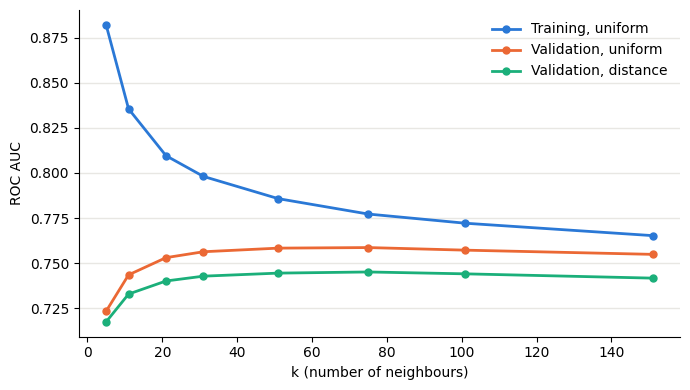

In [10]:
# ---  k-NN fit diagnosis - training vs validation AUC ---
# With weights='distance' every training row is its own nearest neighbour, so training AUC is 1.0
# by construction. Read the uniform lines for the gap between training and validation.
results = pd.DataFrame(knn_grid.cv_results_)
uniform = results[results['param_model__weights'] == 'uniform']
distance = results[results['param_model__weights'] == 'distance']
ks = uniform['param_model__n_neighbors'].astype(int)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, uniform['mean_train_score'], color='#2a78d6', lw=2, marker='o', ms=5, label='Training, uniform')
ax.plot(ks, uniform['mean_test_score'], color='#eb6834', lw=2, marker='o', ms=5, label='Validation, uniform')
ax.plot(ks, distance['mean_test_score'], color='#1baf7a', lw=2, marker='o', ms=5, label='Validation, distance')
ax.set_xlabel('k (number of neighbours)')
ax.set_ylabel('ROC AUC')
ax.grid(axis='y', color='#e8e7e3', lw=1)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [11]:
# ---  decision tree, tuning max_depth and min_samples_leaf with 5-fold CV on training ---
tree = Pipeline([('prep', make_preprocess(num_cols, cat_cols)),
                 ('model', DecisionTreeClassifier(random_state=42))])
tree_grid = GridSearchCV(tree, {'model__max_depth': [2, 4, 6, 8, 10, 12, 15, 20, None],
                                'model__min_samples_leaf': [1, 10, 50, 100, 200, 400, 800, 1600]},
                         scoring='roc_auc', cv=cv, n_jobs=-1, return_train_score=True)
tree_grid.fit(X_train, y_train)
print('best:', tree_grid.best_params_, '| CV AUC %.3f' % tree_grid.best_score_)

best: {'model__max_depth': 15, 'model__min_samples_leaf': 200} | CV AUC 0.779


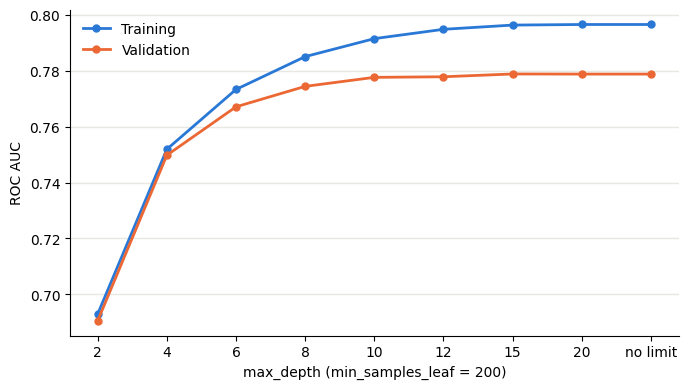

In [12]:
# ---  decision tree fit diagnosis - training vs validation AUC ---
results = pd.DataFrame(tree_grid.cv_results_)
best_leaf = tree_grid.best_params_['model__min_samples_leaf']
curve = results[results['param_model__min_samples_leaf'] == best_leaf]
depths = curve['param_model__max_depth'].astype(str).replace('None', 'no limit')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, curve['mean_train_score'], color='#2a78d6', lw=2, marker='o', ms=5, label='Training')
ax.plot(depths, curve['mean_test_score'], color='#eb6834', lw=2, marker='o', ms=5, label='Validation')
ax.set_xlabel(f'max_depth (min_samples_leaf = {best_leaf})')
ax.set_ylabel('ROC AUC')
ax.grid(axis='y', color='#e8e7e3', lw=1)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

We tuned two hyperparameters each for k-NN and a decision tree, scoring every setting by 5-fold cross-validation on the 2015–16 training data only. The test set isn’t used at this stage.

k-NN fits this question if bookings with similar characteristics tend to end the same way. The decision tree fits because cancellation risk likely depends on combinations of features that it can show as readable rules.

For k-NN, we tuned k from 5 to 151 and weights as either uniform or distance. The best setting was k = 75 with uniform weights, with a CV AUC of 0.759. At k = 5, training AUC is 0.882 but validation AUC is only 0.723, so k-NN overfits when k is small.

For the decision tree, we tuned max_depth from 2 to no limit and min_samples_leaf from 1 to 1,600. The best tree had a depth of 15 and a minimum leaf size of 200, with a CV AUC of 0.779. The best leaf size first landed at 200, the top of our original range. We extended the range to 1,600 and 200 stayed the best.

At each model’s best setting, training scores are about 0.02 higher than validation (k-NN 0.777 vs 0.759, tree 0.797 vs 0.779), so neither model overfits much. The decision tree leads k-NN by 0.020 in AUC and goes into Part 5 as the stronger candidate.


# Part 5: Results on 2017

In [13]:
# ---  score the baseline and every model on the 2017 test set ---
# 0.5 is a placeholder cutoff. Part 7 chooses the real one from what each error costs.
knn_best = knn_grid.best_estimator_
tree_best = tree_grid.best_estimator_
rows = []
for name, model in [('baseline', baseline), ('lead time alone', lead_only),
                    ('lead time + market segment', lead_segment), ('k-NN (tuned)', knn_best),
                    ('decision tree (tuned)', tree_best)]:
    fitted = model.fit(X_train, y_train)
    proba = fitted.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({'model': name, 'AUC': roc_auc_score(y_test, proba), 'accuracy': accuracy_score(y_test, pred),
                 'cancellations caught': recall_score(y_test, pred),
                 'precision': precision_score(y_test, pred, zero_division=0)})
print(pd.DataFrame(rows).set_index('model').round(3).to_string())

                              AUC  accuracy  cancellations caught  precision
model                                                                       
baseline                    0.500     0.682                 0.000      0.000
lead time alone             0.631     0.682                 0.004      0.549
lead time + market segment  0.712     0.692                 0.079      0.618
k-NN (tuned)                0.718     0.721                 0.300      0.631
decision tree (tuned)       0.742     0.735                 0.403      0.629


market segment  bookings  cancel rate %  lead time AUC
     Corporate      1374           15.3          0.726
     Online TA     22646           40.9          0.646
        Direct      4623           15.4          0.632
 Offline TA/TO      4517           16.9          0.573
        Groups      3077           20.5          0.522
 Complementary       214           16.4          0.475
      Aviation       110           20.9          0.414


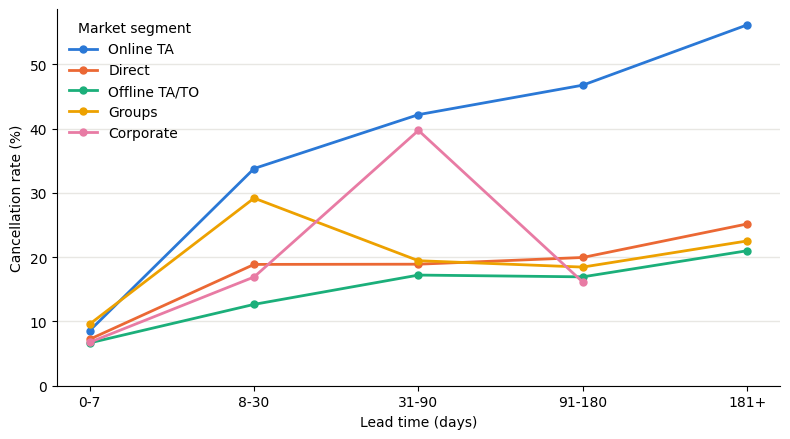

In [14]:
# ---  lead time's AUC inside each market segment ---
rows = []
for segment, part in test.groupby('market_segment'):
    if len(part) >= 100 and part[TARGET].nunique() == 2:
        rows.append({'market segment': segment, 'bookings': len(part), 'cancel rate %': round(part[TARGET].mean() * 100, 1),
                     'lead time AUC': round(roc_auc_score(part[TARGET], part['lead_time']), 3)})
print(pd.DataFrame(rows).sort_values('lead time AUC', ascending=False).to_string(index=False))

# Cancellation rate by lead-time band, largest five segments (bands with 30+ bookings)
bands = pd.cut(test['lead_time'], [-1, 7, 30, 90, 180, 1000], labels=['0-7', '8-30', '31-90', '91-180', '181+'])
largest = test['market_segment'].value_counts().head(5).index
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']

fig, ax = plt.subplots(figsize=(8, 4.5))
for segment, color in zip(largest, colors):
    part = test[test['market_segment'] == segment]
    rate = part.groupby(bands[part.index], observed=True)[TARGET].agg(['mean', 'size'])
    rate = rate[rate['size'] >= 30]
    ax.plot(rate.index.astype(str), rate['mean'] * 100, color=color, lw=2, marker='o', ms=5, label=segment)
ax.set_xlabel('Lead time (days)')
ax.set_ylabel('Cancellation rate (%)')
ax.set_ylim(0, None)
ax.grid(axis='y', color='#e8e7e3', lw=1)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, title='Market segment', loc='upper left')
plt.tight_layout()
plt.show()

In [15]:
# --- the same models under a random split, to show what changed ---
def auc_on(train_part, test_part, model):
    fitted = clone(model).fit(train_part[features], train_part[TARGET])
    return roc_auc_score(test_part[TARGET], fitted.predict_proba(test_part[features])[:, 1])


random_train, random_test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=42)
unique = data.drop_duplicates(subset=features + [TARGET])
unique_train, unique_test = train_test_split(unique, test_size=0.2, stratify=unique[TARGET], random_state=42)

print(pd.DataFrame({
    'random split': {'k-NN': auc_on(random_train, random_test, knn_best), 'decision tree': auc_on(random_train, random_test, tree_best)},
    'duplicates removed first': {'k-NN': auc_on(unique_train, unique_test, knn_best), 'decision tree': auc_on(unique_train, unique_test, tree_best)},
    'train 2015-16, test 2017': {'k-NN': auc_on(train, test, knn_best), 'decision tree': auc_on(train, test, tree_best)},
}).T.round(3).to_string())

                           k-NN  decision tree
random split              0.778          0.793
duplicates removed first  0.758          0.778
train 2015-16, test 2017  0.718          0.742


In [17]:
# --- best model with Non Refund rows in vs out ---
# The best model is the one with the higher cross-validated AUC, so the test set chooses nothing here.
best_name, best_model = ('k-NN', knn_best) if knn_grid.best_score_ > tree_grid.best_score_ else ('decision tree', tree_best)
print('best model by CV:', best_name)

train_in = df[df['arrival_date_year'] < 2017].drop_duplicates(subset=features + [TARGET])
test_in = df[df['arrival_date_year'] == 2017]

rows = []
for label, tr, te in [('Non Refund out', train, test), ('Non Refund in', train_in, test_in)]:
    fitted = clone(best_model).fit(tr[features], tr[TARGET])
    proba = fitted.predict_proba(te[features])[:, 1]
    rows.append({'rows': label, 'test bookings': len(te), 'AUC': roc_auc_score(te[TARGET], proba),
                 'accuracy': accuracy_score(te[TARGET], proba >= 0.5),
                 'always "arrives" accuracy': 1 - te[TARGET].mean()})
print(pd.DataFrame(rows).set_index('rows').round(3).to_string())

best model by CV: decision tree
                test bookings    AUC  accuracy  always "arrives" accuracy
rows                                                                     
Non Refund out          36561  0.742     0.735                      0.682
Non Refund in           40687  0.809     0.756                      0.613



Ultimately, our models are scored against the 2017 test portion of the data, and no model was built on top of this portion.

To reiterate some information from above, we use AUC as the main score, because the 0.5 cutoff behind accuracy is only a placeholder until Part 7. The baseline scores 0.500, which is the same as guessing. Lead time alone reaches 0.631, and adding market segment raises it to 0.712. k-NN scores 0.718 and the decision tree scores 0.742, the best of the five. Both tuned models scored about 0.04 lower on 2017 than in cross-validation, likely because 2017 has more cancellations than the training data (31.8% against 25.0%).

To answer the first part of our question, lead time on its own beats guessing but is a weak predictor. Combined with market segment, it comes close to the full models: 0.712 against 0.718 for k-NN and 0.742 for the tree.

To answer the second part, how well lead time predicts does vary by segment. It works best for Corporate (0.726), followed by Online TA (0.646), the largest segment with 22,646 bookings. Direct reaches 0.632, Offline TA/TO 0.573, and Groups only 0.522, close to guessing. The chart shows the same pattern: for Online TA, the cancellation rate climbs from about 9% to 56% as lead time grows, while for Groups and Offline TA/TO it stays mostly flat.

Under a random split, the tree scores 0.793 and k-NN 0.778, which overstates how well the models would do on bookings that haven’t happened yet. Keeping the Non Refund bookings would raise the tree’s AUC to 0.809, but only because those rows are easy to flag, so leaving them out was the honest choice.

Overall, lead time helps, but how much depends on how the booking came in. It is a strong signal for Online TA and Corporate bookings and nearly useless for Groups.